# Machine Learning Engineering - Taller 3
## Ejercicio 2 Prueba con ML Flow

## Parte 0. Instalación e imports

> Si `import mlflow.sklearn` falla con `cannot import name 'DataType'`, la instalación quedó mezclada. Correr **en una terminal** (no en el notebook) y reiniciar el kernel:
> ```
> pip uninstall -y mlflow mlflow-skinny mlflow-tracing
> pip install -U mlflow scikit-learn pandas numpy matplotlib
> ```

In [1]:
import warnings
import logging
warnings.filterwarnings("ignore")
logging.getLogger("mlflow").setLevel(logging.ERROR)

from datetime import datetime, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
from sklearn.model_selection import train_test_split, cross_val_score, TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Tracking local (archivo SQLite) -> no requiere levantar un servidor para registrar
mlflow.set_tracking_uri("sqlite:///mlflow.db")
apple_experiment = mlflow.set_experiment("Apple_Models")
print("MLflow:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())

2026/10/13 18:14:29 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/13 18:14:29 INFO mlflow.store.db.utils: Updating database tables
2026/10/13 18:14:35 INFO mlflow.tracking.fluent: Experiment with name 'Apple_Models' does not exist. Creating a new experiment.


MLflow: 3.17.1
Tracking URI: sqlite:///mlflow.db


---
# Parte A. Tutorial original (sin modificaciones)
Código del tutorial *Logging your first model* de MLflow: generador de datos sintéticos de ventas de manzanas y entrenamiento de un `RandomForestRegressor`.
(Únicos cambios de compatibilidad: `fillna(method="bfill", inplace=True)` se cambió por `.bfill()`, y el modelo se guarda con `cloudpickle` porque las versiones recientes de MLflow bloquean por defecto el formato `skops` con modelos de árboles.)

In [2]:
def generate_apple_sales_data_with_promo_adjustment(base_demand: int = 1000, n_rows: int = 5000):
    """
    Generates a synthetic dataset for predicting apple sales demand with seasonality
    and inflation. (Código del tutorial de MLflow)
    """
    # Set seed for reproducibility
    np.random.seed(9999)

    # Create date range
    dates = [datetime.now() - timedelta(days=i) for i in range(n_rows)]
    dates.reverse()

    # Generate features
    df = pd.DataFrame(
        {
            "date": dates,
            "average_temperature": np.random.uniform(10, 35, n_rows),
            "rainfall": np.random.exponential(5, n_rows),
            "weekend": [(date.weekday() >= 5) * 1 for date in dates],
            "holiday": np.random.choice([0, 1], n_rows, p=[0.97, 0.03]),
            "price_per_kg": np.random.uniform(0.5, 3, n_rows),
            "month": [date.month for date in dates],
        }
    )

    # Introduce inflation over time (years)
    df["inflation_multiplier"] = 1 + (df["date"].dt.year - df["date"].dt.year.min()) * 0.03

    # Incorporate seasonality due to apple harvests
    df["harvest_effect"] = np.sin(2 * np.pi * (df["month"] - 3) / 12) + np.sin(2 * np.pi * (df["month"] - 9) / 12)

    # Modify the price_per_kg based on harvest effect
    df["price_per_kg"] = df["price_per_kg"] - df["harvest_effect"] * 0.5

    # Adjust promo periods to coincide with periods lagging peak harvest by 1 month
    peak_months = [4, 10]  # months following the peak availability
    df["promo"] = np.where(df["month"].isin(peak_months), 1, np.random.choice([0, 1], n_rows, p=[0.85, 0.15]))

    # Generate target variable based on features
    base_price_effect = -df["price_per_kg"] * 50
    seasonality_effect = df["harvest_effect"] * 50
    promo_effect = df["promo"] * 200
    df["demand"] = (
        base_demand
        + base_price_effect
        + seasonality_effect
        + promo_effect
        + df["weekend"] * 300
        + np.random.normal(0, 50, n_rows)
    ) * df["inflation_multiplier"]

    # Add previous day's demand
    df["previous_days_demand"] = df["demand"].shift(1)
    df["previous_days_demand"] = df["previous_days_demand"].bfill()  # fill the first row

    # Drop temporary columns
    df.drop(columns=["inflation_multiplier", "harvest_effect", "month"], inplace=True)

    return df


data = generate_apple_sales_data_with_promo_adjustment(base_demand=1_000, n_rows=1_000)
data[-20:]

,date,average_temperature,rainfall,weekend,holiday,price_per_kg,promo,demand,previous_days_demand
980,2026-09-24 18:14:35.208873,34.130183,1.454065,0,0,1.449177,0,971.802447,1001.085782
981,2026-09-25 18:14:35.208873,32.353643,9.462859,0,0,2.856503,0,818.951553,971.802447
982,2026-09-26 18:14:35.208873,18.816833,0.391470,1,0,1.326429,0,1281.352029,818.951553
983,2026-09-27 18:14:35.208873,34.533012,2.120477,1,0,0.970131,0,1357.385504,1281.352029
984,2026-09-28 18:14:35.208873,23.057202,2.365705,0,0,1.049931,0,991.427049,1357.385504
985,2026-09-29 18:14:35.208873,34.810165,3.089005,0,0,2.035149,0,974.971149,991.427049
986,2026-09-30 18:14:35.208873,29.208905,3.673292,0,0,2.518098,0,1056.249547,974.971149
987,2026-10-01 18:14:35.208873,16.428676,4.077782,0,0,1.268979,1,1275.118915,1056.249547
988,2026-10-02 18:14:35.208873,32.067512,2.734454,0,0,0.762317,1,1252.492007,1275.118915
989,2026-10-03 18:14:35.208873,31.938203,13.883486,1,0,1.153301,1,1497.040470,1252.492007


In [3]:
# Run constants del tutorial
run_name = "apples_rf_test"
artifact_path = "rf_apples"

# Split the data into features and target and drop irrelevant date field and target field
X = data.drop(columns=["date", "demand"])
y = data["demand"]

# Split the data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

params = {
    "n_estimators": 100,
    "max_depth": 6,
    "min_samples_split": 10,
    "min_samples_leaf": 4,
    "bootstrap": True,
    "oob_score": False,
    "random_state": 888,
}

# Train the RandomForestRegressor
rf = RandomForestRegressor(**params)
rf.fit(X_train, y_train)

# Predict on the validation set and calculate error metrics
y_pred = rf.predict(X_val)
mae = mean_absolute_error(y_val, y_pred)
mse = mean_squared_error(y_val, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_val, y_pred)
metrics = {"mae": mae, "mse": mse, "rmse": rmse, "r2": r2}

# Initiate the MLflow run context
with mlflow.start_run(run_name=run_name) as run:
    mlflow.set_tag("etapa", "A_tutorial_original")
    mlflow.log_params(params)
    mlflow.log_metrics(metrics)
    mlflow.sklearn.log_model(sk_model=rf, input_example=X_val, name=artifact_path, serialization_format="cloudpickle")

print({k: round(v, 4) for k, v in metrics.items()})

2026/10/13 18:14:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


{'mae': 47.3746, 'mse': 3616.7833, 'rmse': np.float64(60.1397), 'r2': 0.8853}


---
# Parte B. Análisis del tutorial y mejoras
Primero se revisa qué tan buenos son los datos y el algoritmo propuestos. Las siguientes celdas muestran la evidencia de cada problema.

In [4]:
# Hallazgo 1: ¿qué variables realmente influyen en la demanda en los datos del tutorial?
print("Correlación con la demanda (datos del tutorial):")
print(data.drop(columns=["date"]).corr()["demand"].drop("demand").round(3).sort_values())

# Hallazgo 2: el harvest_effect del tutorial = sin(2*pi*(m-3)/12) + sin(2*pi*(m-9)/12). Los dos senos están desfasados 6 meses (medio período) -> se anulan
meses = np.arange(1, 13)
harvest_tutorial = np.sin(2 * np.pi * (meses - 3) / 12) + np.sin(2 * np.pi * (meses - 9) / 12)
print("\nMáximo |harvest_effect| del tutorial en los 12 meses:", np.abs(harvest_tutorial).max())

# Hallazgo 3: importancia de variables del Random Forest del tutorial
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nImportancia de variables (RF del tutorial):")
print(imp.round(3))

Correlación con la demanda (datos del tutorial):
price_per_kg           -0.218
average_temperature    -0.079
holiday                -0.051
rainfall               -0.021
previous_days_demand    0.322
promo                   0.505
weekend                 0.767
Name: demand, dtype: float64

Máximo |harvest_effect| del tutorial en los 12 meses: 2.220446049250313e-16

Importancia de variables (RF del tutorial):
weekend                 0.627
promo                   0.284
price_per_kg            0.062
average_temperature     0.010
previous_days_demand    0.010
rainfall                0.007
holiday                 0.000
dtype: float64


**Hallazgos sobre el tutorial**
1. `average_temperature`, `rainfall` y `holiday` se generan pero **no intervienen** en la demanda: son columnas de ruido.
2. El `harvest_effect` (suma de dos senos desfasados 6 meses) **vale 0 en todos los meses**: la estacionalidad de cosecha y el ajuste de precio que dependen de él **no tienen ningún efecto**.
3. Las fechas usan `datetime.now()` y la semilla es global: los datos **cambian cada día** que se ejecuta.
4. `previous_days_demand` rellena la primera fila con `bfill()` (usa un valor *futuro*) y la partición es **aleatoria** en una serie de tiempo: el modelo ve días vecinos del día que va a predecir (fuga de información), lo que da métricas optimistas.
5. La demanda crece por inflación (nominal) y los árboles **no extrapolan**: un Random Forest no puede predecir niveles más altos que los vistos en entrenamiento. Además solo se prueba **un modelo con un solo conjunto de hiperparámetros**.

**Mejoras propuestas**
- *Datos:* fecha inicial fija y `default_rng(seed)` (reproducible); efecto de cosecha corregido (dos picos al año, período de 6 meses); temperatura estacional; la demanda depende también de temperatura, lluvia y feriados; efecto del precio no lineal (logarítmico) y acotado a un mínimo; el rezago se calcula sin `bfill` (se elimina la primera fila); el índice de inflación queda como columna observable.
- *Algoritmo:* partición **cronológica** (entrenar con el pasado, evaluar con el futuro); *feature engineering* (mes en seno/coseno, log del precio); modelar la **demanda real** (deflactada por el índice de inflación) y volver a nominal al predecir, para que los árboles no tengan que extrapolar; validación cruzada con `TimeSeriesSplit`; comparación de varios modelos e hiperparámetros como *nested runs*; gráficas de predicción vs real como artefactos.

In [5]:
# ---------- Datos mejorados (v2) ----------
base_demand = 1000
n_rows = 1000
seed = 9999
rng = np.random.default_rng(seed)

dates = pd.date_range(start="2022-01-01", periods=n_rows, freq="D")      # fecha fija -> reproducible
data2 = pd.DataFrame({"date": dates})
month = data2["date"].dt.month
dayofyear = data2["date"].dt.dayofyear

# Temperatura estacional (antes: uniforme sin relación con la fecha)
data2["average_temperature"] = 22 + 10 * np.sin(2 * np.pi * (dayofyear - 80) / 365) + rng.normal(0, 2, n_rows)
data2["rainfall"] = rng.exponential(5, n_rows)
data2["weekend"] = (data2["date"].dt.weekday >= 5).astype(int)
data2["holiday"] = rng.choice([0, 1], n_rows, p=[0.97, 0.03])
data2["price_per_kg"] = rng.uniform(0.5, 3, n_rows)

# Índice de inflación observable (como un IPC), se conserva como columna
data2["inflation_index"] = 1 + (data2["date"].dt.year - data2["date"].dt.year.min()) * 0.03
# Efecto de cosecha con dos picos por año (el del tutorial se cancelaba a 0)
harvest_effect = np.sin(2 * np.pi * (month - 3) / 6)

# Precio ajustado por cosecha, acotado a un mínimo (con el efecto activo el precio puede acercarse a 0)
data2["price_per_kg"] = (data2["price_per_kg"] - harvest_effect * 0.5).clip(lower=0.3)

data2["promo"] = np.where(month.isin([4, 10]), 1, rng.choice([0, 1], n_rows, p=[0.85, 0.15]))

data2["demand"] = (
    base_demand
    - 100 * np.log(data2["price_per_kg"])          # efecto no lineal del precio
    + harvest_effect * 100
    + data2["promo"] * 200
    + data2["weekend"] * 300
    + data2["holiday"] * 150                       # ahora el feriado sí importa
    + 10 * (data2["average_temperature"] - 22)     # ahora la temperatura sí importa
    - 8 * data2["rainfall"]                        # ahora la lluvia sí importa
    + rng.normal(0, 50, n_rows)
) * data2["inflation_index"]

# Rezago sin bfill: se descarta la primera fila en lugar de usar un valor del futuro
data2["previous_days_demand"] = data2["demand"].shift(1)
data2 = data2.dropna().reset_index(drop=True)

print("Correlación con la demanda (datos mejorados):")
print(data2.drop(columns=["date"]).corr()["demand"].drop("demand").round(3).sort_values())
print("Precio mínimo:", round(data2["price_per_kg"].min(), 3))
data2[-20:]

Correlación con la demanda (datos mejorados):
price_per_kg           -0.405
rainfall               -0.166
inflation_index         0.114
holiday                 0.150
average_temperature     0.325
previous_days_demand    0.537
promo                   0.538
weekend                 0.572
Name: demand, dtype: float64
Precio mínimo: 0.3


,date,average_temperature,rainfall,weekend,holiday,price_per_kg,inflation_index,promo,demand,previous_days_demand
979,2024-09-07,24.481319,4.456037,1,0,2.923186,1.06,0,1316.904523,1044.082201
980,2024-09-08,24.130630,18.990178,1,0,1.007790,1.06,0,1126.475920,1316.904523
981,2024-09-09,24.623561,1.681046,0,0,1.382850,1.06,1,1280.917380,1126.475920
982,2024-09-10,20.975562,5.674153,0,0,2.539725,1.06,0,936.195537,1280.917380
983,2024-09-11,22.478923,9.268260,0,0,1.856553,1.06,0,908.702740,936.195537
984,2024-09-12,21.500690,3.650013,0,0,2.649280,1.06,0,946.917919,908.702740
985,2024-09-13,24.711220,3.806114,0,0,2.546563,1.06,0,873.215623,946.917919
986,2024-09-14,25.033321,3.458377,1,0,2.047927,1.06,1,1469.395338,873.215623
987,2024-09-15,23.273718,2.676114,1,0,0.726443,1.06,0,1322.512086,1469.395338
988,2024-09-16,21.501613,0.158400,0,0,1.869841,1.06,0,1007.972058,1322.512086


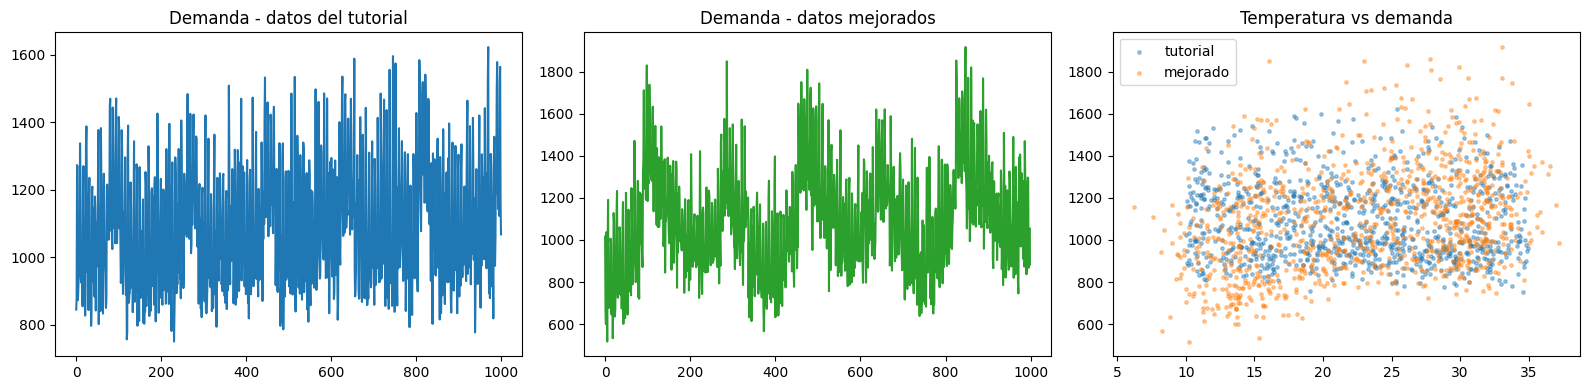

In [6]:
# Comparación visual de datos: tutorial vs mejorados
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(data["demand"].values); axes[0].set_title("Demanda - datos del tutorial")
axes[1].plot(data2["demand"].values, color="tab:green"); axes[1].set_title("Demanda - datos mejorados")
axes[2].scatter(data["average_temperature"], data["demand"], s=6, alpha=0.4, label="tutorial")
axes[2].scatter(data2["average_temperature"], data2["demand"], s=6, alpha=0.4, label="mejorado")
axes[2].set_title("Temperatura vs demanda"); axes[2].legend()
plt.tight_layout()
plt.show()

In [7]:
# ---------- Features y partición cronológica ----------
data2["month_sin"] = np.sin(2 * np.pi * data2["date"].dt.month / 12)
data2["month_cos"] = np.cos(2 * np.pi * data2["date"].dt.month / 12)
data2["log_price"] = np.log(data2["price_per_kg"])
data2["dayofweek"] = data2["date"].dt.dayofweek

data2["prev_demand_real"] = data2["previous_days_demand"] / data2["inflation_index"]   # rezago en términos reales

cols_tutorial = ["average_temperature", "rainfall", "weekend", "holiday", "price_per_kg", "promo", "previous_days_demand"]
cols_features = cols_tutorial + ["month_sin", "month_cos", "log_price"]
cols_real = [c for c in cols_features if c != "previous_days_demand"] + ["prev_demand_real"]

split_idx = int(len(data2) * 0.8)                      # 80% pasado para entrenar, 20% futuro para evaluar
train2 = data2.iloc[:split_idx]
test2 = data2.iloc[split_idx:]
y_train2 = train2["demand"]
y_test2 = test2["demand"]
print("Entrenamiento:", train2["date"].min().date(), "->", train2["date"].max().date())
print("Prueba       :", test2["date"].min().date(), "->", test2["date"].max().date())

Entrenamiento: 2022-01-02 -> 2024-03-10
Prueba       : 2024-03-11 -> 2024-09-26


In [8]:
# ---------- Experimentos mejorados (nested runs) ----------
experimentos = [
    # (nombre, modelo, columnas, ¿modelar demanda real/deflactada?)
    ("rf_receta_tutorial_datos_v2", RandomForestRegressor(**params), cols_tutorial, False),
    ("rf_features_nuevas", RandomForestRegressor(**params), cols_features, False),
    ("rf_demanda_real", RandomForestRegressor(**params), cols_real, True),
    ("ridge_demanda_real", make_pipeline(StandardScaler(), Ridge(alpha=1.0)), cols_real, True),
    ("gbr_demanda_real", GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42), cols_real, True),
    ("rf_tuneado_demanda_real", RandomForestRegressor(n_estimators=300, max_depth=10, min_samples_leaf=2, random_state=42), cols_real, True),
]

with mlflow.start_run(run_name="B_mejoras_v2"):
    mlflow.set_tag("etapa", "B_mejorado")
    mlflow.log_param("split", "cronologico 80/20")
    mlflow.log_param("n_rows", n_rows)

    for nombre, modelo, cols, deflactar in experimentos:
        with mlflow.start_run(run_name=nombre, nested=True):
            mlflow.set_tag("etapa", "B_mejorado")
            mlflow.log_param("modelo", type(modelo).__name__)
            mlflow.log_param("features", ",".join(cols))
            mlflow.log_param("objetivo", "demanda real (deflactada)" if deflactar else "demanda nominal")
            hp = {k: v for k, v in modelo.get_params(deep=False).items() if isinstance(v, (int, float, str, bool, type(None)))}
            mlflow.log_params(hp)

            # Validación cruzada que respeta el orden temporal (RMSE siempre en unidades nominales)
            cv_rmse = []
            for tr, va in TimeSeriesSplit(n_splits=5).split(train2):
                tr_df = train2.iloc[tr]
                va_df = train2.iloc[va]
                d_tr = tr_df["inflation_index"] if deflactar else 1.0
                d_va = va_df["inflation_index"] if deflactar else 1.0
                m = clone(modelo)
                m.fit(tr_df[cols], tr_df["demand"] / d_tr)
                p = m.predict(va_df[cols]) * d_va
                cv_rmse.append(np.sqrt(mean_squared_error(va_df["demand"], p)))
            mlflow.log_metric("cv_rmse_mean", np.mean(cv_rmse))
            mlflow.log_metric("cv_rmse_std", np.std(cv_rmse))

            # Entrenamiento final y evaluación en el futuro (conjunto de prueba)
            d_train = train2["inflation_index"] if deflactar else 1.0
            d_test = test2["inflation_index"] if deflactar else 1.0
            modelo.fit(train2[cols], y_train2 / d_train)
            pred = modelo.predict(test2[cols]) * d_test
            mse_i = mean_squared_error(y_test2, pred)
            mlflow.log_metrics({
                "mae": mean_absolute_error(y_test2, pred),
                "mse": mse_i,
                "rmse": np.sqrt(mse_i),
                "r2": r2_score(y_test2, pred),
            })

            # Gráfica de predicción vs real como artefacto
            fig, ax = plt.subplots(figsize=(9, 3.5))
            ax.plot(test2["date"].values, y_test2.values, label="real")
            ax.plot(test2["date"].values, pred, label="predicho")
            ax.set_title(nombre); ax.legend()
            plt.tight_layout()
            mlflow.log_figure(fig, "prediccion_vs_real.png")
            plt.close(fig)

            if deflactar:
                mlflow.set_tag("nota", "el modelo predice demanda real: multiplicar por inflation_index para obtener demanda nominal")
            mlflow.sklearn.log_model(modelo, name="modelo", input_example=test2[cols].head(5), serialization_format="cloudpickle")
            print(f"{nombre:30s} RMSE: {np.sqrt(mse_i):8.2f} | R2: {r2_score(y_test2, pred):.4f} | CV RMSE: {np.mean(cv_rmse):8.2f}")

2026/10/13 18:15:13 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


rf_receta_tutorial_datos_v2    RMSE:   114.05 | R2: 0.7645 | CV RMSE:   111.97


2026/10/13 18:15:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


rf_features_nuevas             RMSE:   103.38 | R2: 0.8065 | CV RMSE:   127.29


2026/10/13 18:15:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


...

ridge_demanda_real             RMSE:    75.57 | R2: 0.8966 | CV RMSE:    99.78


2026/10/13 18:16:03 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


gbr_demanda_real               RMSE:    71.36 | R2: 0.9078 | CV RMSE:    97.32


2026/10/13 18:16:21 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


rf_tuneado_demanda_real        RMSE:    82.14 | R2: 0.8778 | CV RMSE:   110.84


                                            MAE      RMSE      R2
Tutorial original (RF)                  47.3746   60.1397  0.8853
Receta del tutorial en datos mejorados  92.9769  114.0483  0.7645
Algoritmo mejorado (Gradient Boosting)  55.6853   71.3598  0.9078

Reducción del RMSE (mismos datos): 37.4%


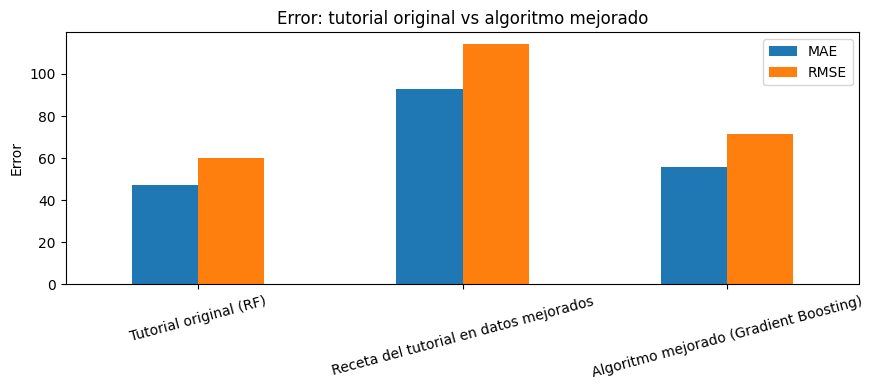

In [9]:
# ===== Comparación: algoritmo original vs algoritmo mejorado =====
import mlflow
import pandas as pd
import matplotlib.pyplot as plt

runs = mlflow.search_runs(experiment_names=["Apple_Models"])
runs = runs.set_index("tags.mlflow.runName")

filas = {
    "Tutorial original (RF)": "apples_rf_test",
    "Receta del tutorial en datos mejorados": "rf_receta_tutorial_datos_v2",
    "Algoritmo mejorado (Gradient Boosting)": "gbr_demanda_real",
}

tabla = pd.DataFrame({
    nombre: {
        "MAE": runs.loc[run, "metrics.mae"],
        "RMSE": runs.loc[run, "metrics.rmse"],
        "R2": runs.loc[run, "metrics.r2"],
    }
    for nombre, run in filas.items()
}).T.round(4)

print(tabla)

mejora = (1 - tabla.loc["Algoritmo mejorado (Gradient Boosting)", "RMSE"] / tabla.loc["Receta del tutorial en datos mejorados", "RMSE"]) * 100
print(f"\nReducción del RMSE (mismos datos): {mejora:.1f}%")

tabla[["MAE", "RMSE"]].plot(kind="bar", figsize=(9, 4), rot=15)
plt.title("Error: tutorial original vs algoritmo mejorado")
plt.ylabel("Error")
plt.tight_layout()
plt.show()